<a href="https://colab.research.google.com/github/panarisivalentino-pixel/analisis-juegos-steam/blob/main/notebooks/02_analisis_principal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Análisis Exploratorio de Datos - Juegos de Steam

## Objetivo del análisis
Determinar qué tipos de videojuegos son los más jugados utilizando distintas métricas del dataset de Steam.

---

## Contenido
1. Introducción y planteamiento del problema  
2. Carga y limpieza de datos  
3. Exploración inicial del dataset  
4. Análisis univariado  
5. Análisis bivariado  
6. Visualizaciones  
7. Conclusiones  

---

## 1. El problema del negocio

La industria de los videojuegos es una de las más grandes del entretenimiento,
con miles de juegos lanzados cada año en plataformas como Steam.

**Pregunta de investigación:**
¿Qué tipos o géneros de videojuegos son los más jugados a nivel mundial?

**Objetivos específicos:**
- Clasificar los videojuegos según su género
- Determinar cuáles presentan mayor nivel de popularidad
- Comparar la distribución entre distintos tipos de juegos
- Identificar patrones de consumo y preferencias

## 2. El set de datos después de la limpieza

Dataset: Steam Games Dataset (Kaggle)
- **122,577 juegos**
- **17 variables**
- **Fuente:** https://www.kaggle.com/datasets/fronkongames/steam-games-dataset

### Variables principales:

**Variables numéricas:**
1. Price: Precio en dólares
2. Peak CCU: Jugadores concurrentes máximos (métrica de popularidad)
3. Positive2: Reseñas positivas
4. Negative: Reseñas negativas
5. Recommendations2: Recomendaciones
6. Average playtime forever: Tiempo promedio jugado (métrica de engagement)
7. Median playtime forever: Tiempo mediano jugado

**Variables categóricas:**

8. Name: Nombre del juego
9. Genre: Género del juego
10. Publishers: Editor/distribuidor
11. Release date: Fecha de lanzamiento
12. Required age: Edad requerida

**Variables booleanas:**

13. Windows2: Disponible en Windows
14. Mac: Disponible en Mac
15. Linux2: Disponible en Linux

Tu problema es:

"¿Qué tipos de videojuegos son los más jugados en el mundo?"

Variables disponibles en tu dataset:
VariableTipo¿Sirve para tu problema?

Peak CCU Numérica✅ SÍ - Mide popularidad (jugadores concurrentes)

Average playtime forever Numérica✅ SÍ - Mide engagement (cuánto se juega)

Positive2 Numérica✅ SÍ - Mide recepción del público

Genre Categórica✅ SÍ - Tu variable clave (tipo de juego)PriceNumérica

⚠️ QUIZÁS - ¿El precio influye en popularidad?PublishersCategórica

⚠️ QUIZÁS - ¿Ciertos publishers dominan?Windows2/Mac/Linux2Booleana

⚠️ QUIZÁS - ¿Plataforma afecta popularidad?NameTexto

❌ NO - Nombre del juego no es analizableRelease dateFecha

⚠️ QUIZÁS - ¿Juegos nuevos son más populares?

Las 4 columnas que vamos a usar:
Peak CCU (Numérica) :Mide la popularidad instantánea de un juego (cantidad máxima de jugadores concurrentes). Es la métrica directa de "qué tan jugado" es un juego en su momento pico.

Average playtime forever (Numérica): Mide el engagement total (cuántas horas en promedio le dedican los jugadores). Un juego puede ser popular pero poco jugado, o viceversa. Esta métrica complementa a Peak CCU.

Genre (Categórica) :Es la variable central del problema. Queremos saber qué TIPOS de juegos son más jugados, por lo que necesitamos agrupar por género y comparar.

Price (Numérica) :Queremos explorar si el precio influye en la popularidad. ¿Los juegos caros son menos jugados? ¿Los gratuitos dominan el mercado?

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
dataset = pd.read_csv("cleaned_games_data.csv", encoding='latin1', engine='python', on_bad_lines='skip')

dataset.head()

,Name,Release date,Peak CCU,Required age,Price,Supported languages,audio languages,Windows2,Mac,Linux2,Positive2,Negative,Recommendations2,Average playtime forever,Median playtime forever,Publishers,Genre
0,Re;quartz,2022-08-12,0,0,34.99,"['Japanese', 'Simplified Chinese']",[],True,True,False,20,2,0,0,0,B-cluster,Adventure
1,Butterfly's Poison; Blood Chains,2023-06-13,0,0,29.24,"['English', 'Japanese']",['Japanese'],True,False,False,60,2,0,0,0,PROTOTYPE,Adventure
2,Death end re;Quest: Code Z,2025-08-27,0,0,19.99,"['English', 'Japanese', 'Traditional Chinese',...","['Japanese', 'Simplified Chinese']",True,False,False,0,0,0,0,0,"Idea Factory International, Inc.","RPG,Strategy"
3,ANONYMOUS;CODE,2023-09-08,2,0,17.35,"['English', 'Japanese', 'Traditional Chinese',...","['English', 'Japanese', 'Simplified Chinese']",True,False,False,341,73,435,109,109,"Spike Chunsoft Co., Ltd.",Adventure
4,CHAOS;CHILD,2019-01-22,33,0,12.49,"['English', 'Japanese']",['Japanese'],True,False,False,3094,203,3443,1251,1245,"Spike Chunsoft Co., Ltd.",Adventure


In [ ]:
dataset.shape

(120919, 17)

#Info Sobre el dataset

### Detalles del DataFrame

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120919 entries, 0 to 120918
Data columns (total 17 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Name                      120919 non-null  object 
 1   Release date              120919 non-null  object 
 2   Peak CCU                  120919 non-null  int64  
 3   Required age              120919 non-null  object 
 4   Price                     120919 non-null  float64
 5   Supported languages       120919 non-null  object 
 6    audio languages          120919 non-null  object 
 7   Windows2                  120919 non-null  bool   
 8   Mac                       120919 non-null  bool   
 9   Linux2                    120919 non-null  bool   
 10  Positive2                 120919 non-null  int64  
 11  Negative                  120919 non-null  int64  
 12  Recommendations2          120919 non-null  int64  
 13  Average playtime forever  120919 non-null  i

In [ ]:
dataset.isnull().sum()

,0
Name,0
Release date,0
Peak CCU,0
Required age,0
Price,0
Supported languages,0
audio languages,0
Windows2,0
Mac,0
Linux2,0


In [ ]:
dataset.nunique()

,0
Name,118974
Release date,5081
Peak CCU,1109
Required age,17
Price,877
Supported languages,18896
audio languages,3596
Windows2,2
Mac,2
Linux2,2


#4.1 Análisis de cada variable de manera individual (Análisis Univariado)

Nos permite entender las características generales de cada variable de nuestro set de datos.

In [ ]:
variables_analisis = ['Peak CCU', 'Average playtime forever', 'Price', 'Genre']

print("Variables seleccionadas para el análisis:")
for i, var in enumerate(variables_analisis, 1):
    print(f"  {i}. {var}")

print("\n" + "="*80)
print("INFORMACIÓN DE LAS VARIABLES SELECCIONADAS")
print("="*80)
dataset[variables_analisis].info()

Variables seleccionadas para el análisis:
  1. Peak CCU
  2. Average playtime forever
  3. Price
  4. Genre

INFORMACIÓN DE LAS VARIABLES SELECCIONADAS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120919 entries, 0 to 120918
Data columns (total 4 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Peak CCU                  120919 non-null  int64  
 1   Average playtime forever  120919 non-null  int64  
 2   Price                     120919 non-null  float64
 3   Genre                     120919 non-null  object 
dtypes: float64(1), int64(2), object(1)
memory usage: 3.7+ MB


###Peak CCU

###Peak CCU (Visualización con escala logarítmica)

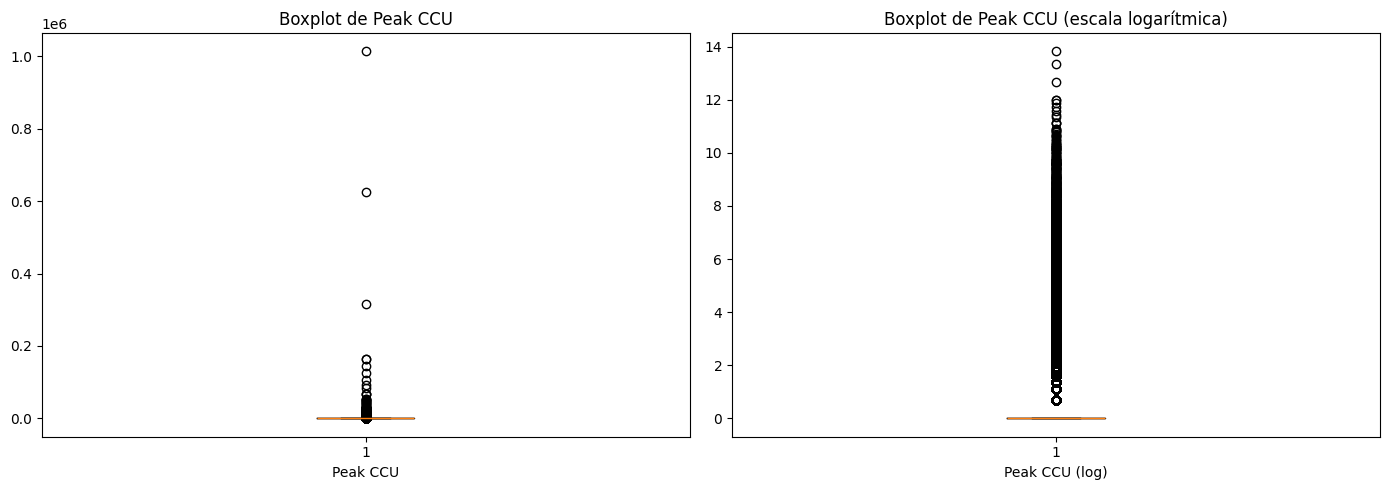

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot de Peak CCU original
axes[0].boxplot(dataset['Peak CCU'])
axes[0].set_xlabel('Peak CCU')
axes[0].set_title('Boxplot de Peak CCU')

# Boxplot de Peak CCU con escala logarítmica
peak_ccu_log = np.log1p(dataset['Peak CCU'])
axes[1].boxplot(peak_ccu_log)
axes[1].set_xlabel('Peak CCU (log)')
axes[1].set_title('Boxplot de Peak CCU (escala logarítmica)')

plt.tight_layout()
plt.show()

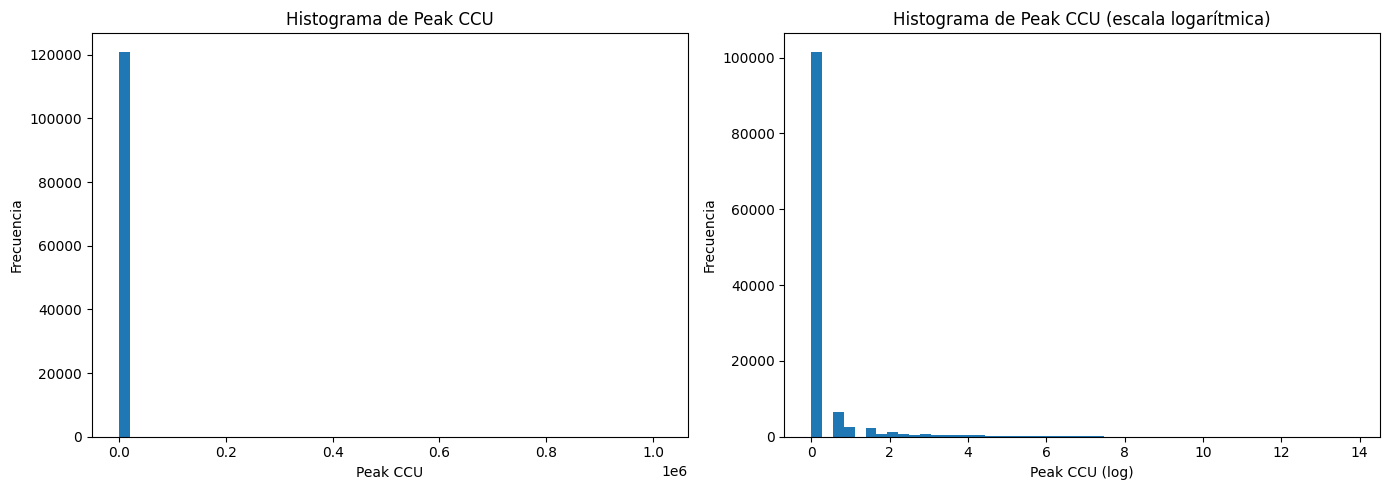

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de Peak CCU original
axes[0].hist(dataset['Peak CCU'], bins=50)
axes[0].set_xlabel('Peak CCU')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title('Histograma de Peak CCU')

# Histograma de Peak CCU con escala logarítmica (usando np.log1p para manejar ceros)
peak_ccu_log = np.log1p(dataset['Peak CCU'])
axes[1].hist(peak_ccu_log, bins=50)
axes[1].set_xlabel('Peak CCU (log)')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Histograma de Peak CCU (escala logarítmica)')

plt.tight_layout()
plt.show()

“El boxplot y el histograma muestran que la distribución de Peak CCU es altamente asimétrica hacia la derecha. La mayoría de los juegos presenta valores bajos de jugadores concurrentes, mientras que unos pocos títulos concentran valores extremadamente altos, generando numerosos outliers.”

####Qué significa en términos reales
El mercado de videojuegos es ultra desigual

Pocos juegos (ej: AAA) → millones de jugadores

La mayoría → casi nadie los juega

In [ ]:
media_peak_ccu = dataset['Peak CCU'].mean()
mediana_peak_ccu = dataset['Peak CCU'].median()
desvio_peak_ccu = dataset['Peak CCU'].std()
min_peak_ccu = dataset['Peak CCU'].min()
max_peak_ccu = dataset['Peak CCU'].max()

print(f"Media: {media_peak_ccu}")
print(f"Mediana: {mediana_peak_ccu}")
print(f"Desvío estándar: {desvio_peak_ccu}")
print(f"Valor mínimo: {min_peak_ccu}")
print(f"Valor máximo: {max_peak_ccu}")

Media: 55.2915753520952
Mediana: 0.0
Desvío estándar: 3755.4337262342674
Valor mínimo: 0
Valor máximo: 1013936


La media (54.61) es considerablemente mayor que la mediana (0), lo que indica una distribución altamente asimétrica hacia la derecha. Esto sugiere que la mayoría de los juegos presenta valores de Peak CCU muy bajos o incluso nulos, mientras que unos pocos juegos alcanzan valores extremadamente altos.

El desvío estándar (3729.97) es muy elevado en relación con la media, lo que evidencia una gran dispersión en los datos y refuerza la idea de que existen outliers significativos

El valor mínimo es 0, indicando que hay juegos sin jugadores concurrentes registrados, mientras que el valor máximo supera el millón de jugadores, lo que confirma la presencia de casos excepcionales que dominan la distribución.

“En conjunto, estos resultados muestran que la popularidad de los videojuegos no se distribuye de manera uniforme, sino que está altamente concentrada en un pequeño grupo de títulos muy exitosos, mientras que la gran mayoría tiene una presencia marginal.”

###Average playtime

###Average playtime forever (Visualización con escala logarítmica)

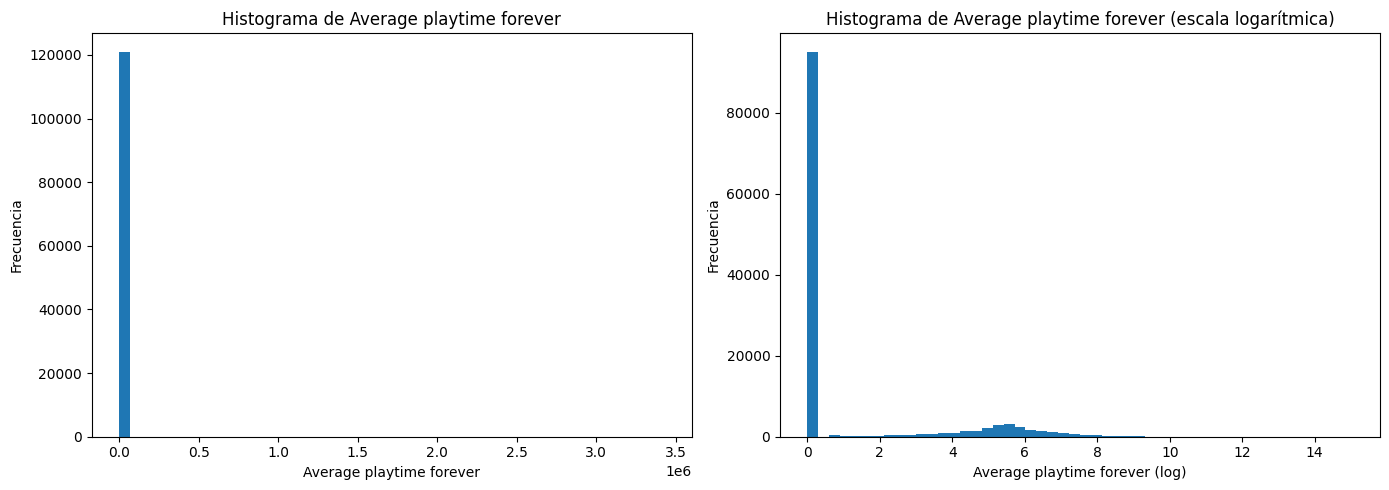

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de Average playtime forever original
axes[0].hist(dataset['Average playtime forever'], bins=50)
axes[0].set_xlabel('Average playtime forever')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title('Histograma de Average playtime forever')

# Histograma de Average playtime forever con escala logarítmica (usando np.log1p para manejar ceros)
avg_playtime_log = np.log1p(dataset['Average playtime forever'])
axes[1].hist(avg_playtime_log, bins=50)
axes[1].set_xlabel('Average playtime forever (log)')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Histograma de Average playtime forever (escala logarítmica)')

plt.tight_layout()
plt.show()

La distribución del tiempo de juego promedio presenta una fuerte asimetría positiva. La mayoría de los juegos registra valores muy bajos de tiempo de juego, mientras que un pequeño grupo concentra valores extremadamente altos, generando numerosos outliers.

#### Qué significa esto en la práctica
Hay juegos que:
- casi nadie juega

- o se juega muy poco tiempo

Y otros que:
- generan muchisimo engagement

- donde los usuarios pasan cientos o miles de horas

In [ ]:
media_average_playtime_forever = dataset['Average playtime forever'].mean()
mediana_average_playtime_forever = dataset['Average playtime forever'].median()
desvio_average_playtime_forever = dataset['Average playtime forever'].std()
min_average_playtime_forever = dataset['Average playtime forever'].min()
max_average_playtime_forever = dataset['Average playtime forever'].max()

print(f"Media: {media_average_playtime_forever}")
print(f"Mediana: {mediana_average_playtime_forever}")
print(f"Desvío estándar: {desvio_average_playtime_forever}")
print(f"Valor mínimo: {min_average_playtime_forever}")
print(f"Valor máximo: {max_average_playtime_forever}")

Media: 207.56170659697815
Mediana: 0.0
Desvío estándar: 11280.948380836178
Valor mínimo: 0
Valor máximo: 3429544


###Price

In [ ]:
media_price = dataset['Price'].mean()
mediana_price = dataset['Price'].median()
desvio_price = dataset['Price'].std()
min_price = dataset['Price'].min()
max_price = dataset['Price'].max()

print(f"Media: {media_price:.2f}")
print(f"Mediana: {mediana_price:.2f}")
print(f"Desvío estándar: {desvio_price:.2f}")
print(f"Mínimo: {min_price}")
print(f"Máximo: {max_price}")

Media: 5.91
Mediana: 4.24
Desvío estándar: 12.10
Mínimo: 0.0
Máximo: 999.98


In [ ]:
import plotly.graph_objects as go
import numpy as np

# Crear el gráfico
fig = go.Figure()

# Agregar histograma escala normal
fig.add_trace(
    go.Histogram(
        x=dataset['Price'],
        nbinsx=50,
        name='Escala Normal',
        marker_color='steelblue',
        visible=True  # Visible por defecto
    )
)

# Agregar histograma escala logarítmica
fig.add_trace(
    go.Histogram(
        x=np.log1p(dataset['Price']),
        nbinsx=50,
        name='Escala Logarítmica',
        marker_color='coral',
        visible=False  # Oculto por defecto
    )
)

# Crear botones para alternar entre escalas
fig.update_layout(
    updatemenus=[
        dict(
            type="buttons",
            direction="left",
            buttons=list([
                dict(
                    args=[{"visible": [True, False]},
                          {"xaxis.title": "Precio (USD)"}],
                    label="Escala Normal",
                    method="update"
                ),
                dict(
                    args=[{"visible": [False, True]},
                          {"xaxis.title": "Precio (USD, log)"}],
                    label="Escala Logarítmica",
                    method="update"
                )
            ]),
            pad={"r": 10, "t": 10},
            showactive=True,
            x=0.0,
            xanchor="left",
            y=1.15,
            yanchor="top"
        ),
    ],
    title="Distribución de Precios (Cambia la escala con los botones)",
    xaxis_title="Precio (USD)",
    yaxis_title="Frecuencia",
    height=600,
    width=1000
)

fig.show()

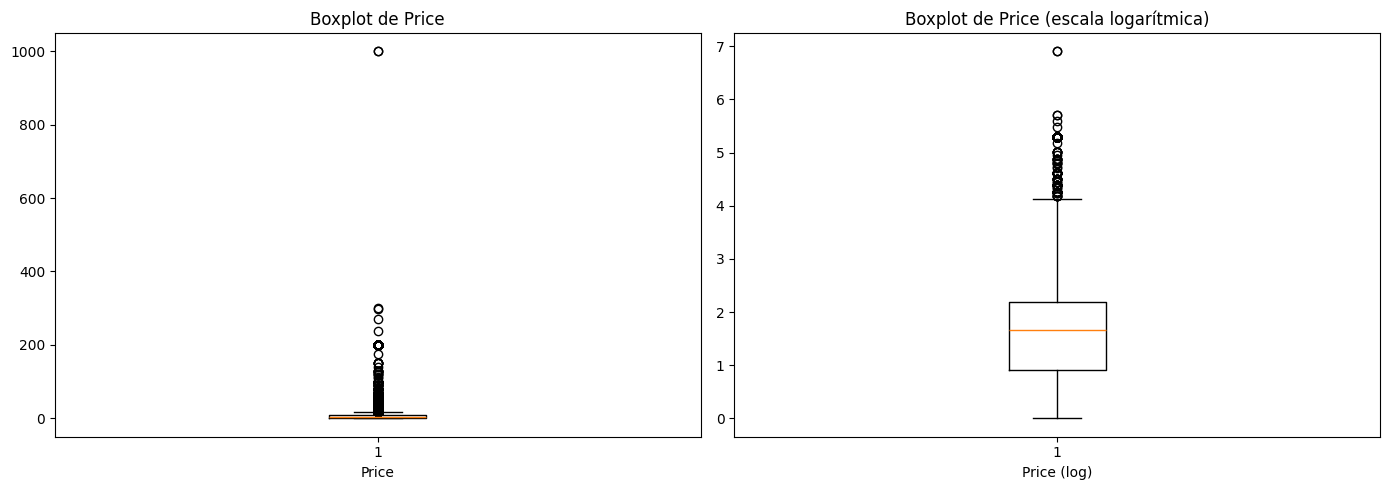

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot de Price original
axes[0].boxplot(dataset['Price'])
axes[0].set_xlabel('Price')
axes[0].set_title('Boxplot de Price')

# Boxplot de Price con escala logarítmica
prices_log = np.log1p(dataset['Price'])
axes[1].boxplot(prices_log)
axes[1].set_xlabel('Price (log)')
axes[1].set_title('Boxplot de Price (escala logarítmica)')

plt.tight_layout()
plt.show()

###Genre

In [ ]:
print(f"Valores únicos en Genre: {dataset['Genre'].nunique()}")
print(f"\nEjemplos de valores:")
print(dataset['Genre'].dropna().head(10).values)

Valores únicos en Genre: 2850

Ejemplos de valores:
['Adventure' 'Adventure' 'RPG,Strategy' 'Adventure' 'Adventure'
 'Adventure' 'Adventure' 'Adventure' 'Indie,Simulation' 'Indie,Simulation']


####Separar géneros múltiples y contar cada uno

El siguiente código procesa la columna 'Genre' (Género), que puede contener múltiples géneros por juego separados por comas. El objetivo es:
1. Separar cada género individualmente.
2. Contar la frecuencia de aparición de cada género.
3. Identificar y visualizar los 15 géneros de videojuegos más comunes en el dataset mediante un gráfico de barras.

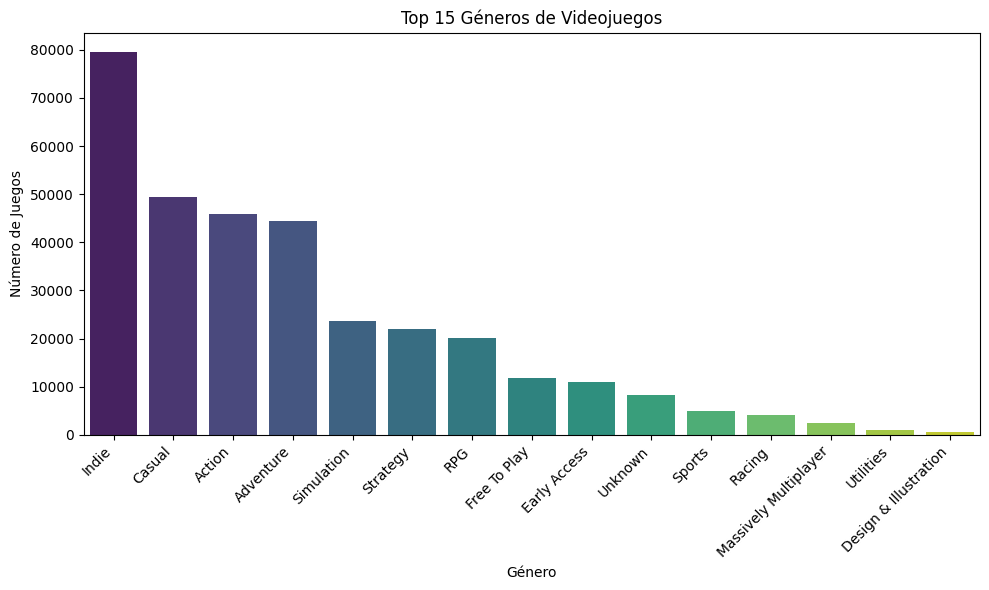

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'cleaned_games_data.csv' is available in the environment
dataset = pd.read_csv("cleaned_games_data.csv", encoding='latin1', engine='python', on_bad_lines='skip')

# Dividir los géneros de cada juego (si hay múltiples) y expandirlos en filas separadas.
# Primero, se eliminan los valores nulos en 'Genre' para evitar errores.
# Luego, se divide la cadena de géneros por la coma.
# 'explode()' transforma cada elemento de la lista resultante en una fila nueva.
# Finalmente, 'str.strip()' elimina espacios en blanco al inicio o final de cada género.
genres_split = dataset['Genre'].dropna().str.split(',').explode().str.strip()

# Contar la frecuencia de cada género único y seleccionar los 15 más populares.
top_genres = genres_split.value_counts().head(15)

# Crear una figura para el gráfico con un tamaño específico (10 pulgadas de ancho, 6 de alto).
plt.figure(figsize=(10, 6))
# Generar un gráfico de barras utilizando seaborn.
# El eje X mostrará los nombres de los géneros (índice de top_genres).
# El eje Y mostrará el conteo de cada género (valores de top_genres).
# Se usa la paleta de colores 'viridis'.
sns.barplot(x=top_genres.index, y=top_genres.values, palette='viridis', hue=top_genres.index, legend=False)
# Establecer el título del gráfico.
plt.title('Top 15 Géneros de Videojuegos')
# Establecer la etiqueta del eje X.
plt.xlabel('Género')
# Establecer la etiqueta del eje Y.
plt.ylabel('Número de Juegos')
# Rotar las etiquetas del eje X 45 grados para mejorar la legibilidad y alinearlas a la derecha.
plt.xticks(rotation=45, ha='right')
# Ajustar automáticamente los parámetros de la subtrama para que quepa la figura.
plt.tight_layout()
# Mostrar el gráfico.
plt.show()

## 4.2 Análisis Bivariado — Peak CCU vs. cada variable

El análisis bivariado nos permite explorar la relación entre **Peak CCU** (nuestra métrica principal de popularidad) y cada una de las demás variables del dataset. El objetivo es identificar qué variables están más asociadas con la popularidad de un videojuego en Steam.

### Peak CCU vs. Price (Numérica)

In [ ]:
import plotly.express as px

# Crear métrica de "popularidad total" (para tamaño de puntos)
dataset['Total_Players'] = dataset['Peak CCU'] + dataset['Average playtime forever']

# Tomar muestra
sample = dataset.sample(n=8000, random_state=42)

# Scatter plot con TAMAÑO variable
fig = px.scatter(
    sample,
    x='Price',
    y='Peak CCU',
    size='Average playtime forever',  # Tamaño según engagement
    color='Genre',
    hover_data={
        'Name': True,
        'Genre': True,
        'Average playtime forever': ':,.0f',
        'Positive2': ':,.0f',
        'Price': ':.2f',
        'Peak CCU': ':,.0f'
    },
    title='Peak CCU vs. Precio - Tamaño = Engagement (Average Playtime)',
    opacity=0.5,
    log_y=True,
    size_max=30  # Tamaño máximo de puntos
)

fig.update_layout(
    xaxis_title="Precio (USD)",
    yaxis_title="Peak CCU (escala logarítmica)",
    height=700,
    width=1400,
    hovermode='closest'
)

fig.show()

El gráfico de dispersión con la escala logarítmica para 'Peak CCU' nos permite observar una concentración masiva de juegos con pocos jugadores (parte inferior del gráfico), independientemente de su precio. Parece que la mayoría de los juegos no alcanzan una gran popularidad. Los juegos con mayor 'Peak CCU' son una pequeña minoría, y están distribuidos en diferentes rangos de precios, aunque hay una fuerte concentración en precios bajos y gratuitos.

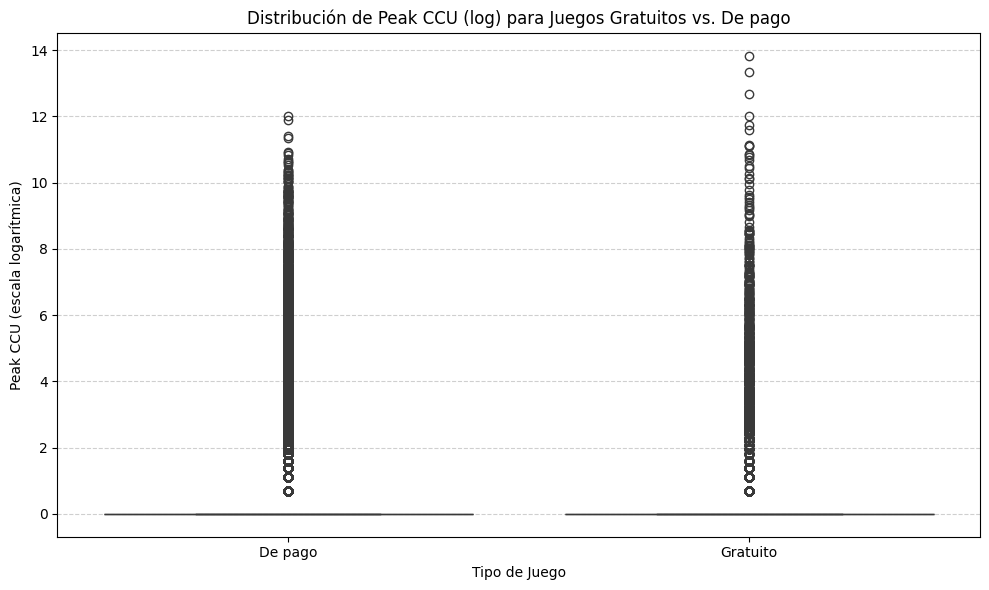

In [ ]:
# Crear la columna 'es_gratuito' nuevamente ya que las celdas anteriores se eliminaron
dataset['es_gratuito'] = dataset['Price'] == 0

# Boxplot de Peak CCU (log) para juegos gratuitos vs. de pago
plt.figure(figsize=(10, 6))
# Usamos np.log1p para manejar valores cero de Peak CCU
sns.boxplot(x='es_gratuito', y=np.log1p(dataset['Peak CCU']), data=dataset, palette='viridis', hue='es_gratuito', legend=False)
plt.xticks([0, 1], ['De pago', 'Gratuito'])
plt.xlabel('Tipo de Juego')
plt.ylabel('Peak CCU (escala logarítmica)')
plt.title('Distribución de Peak CCU (log) para Juegos Gratuitos vs. De pago')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Este boxplot de 'Peak CCU' (en escala logarítmica) comparando juegos gratuitos y de pago, nos da una mejor perspectiva. Podemos observar:

*   **Mediana:** Ambos grupos, gratuitos y de pago, muestran que el 50% de sus juegos tienen un `Peak CCU` muy bajo (cerca de 0 en la escala logarítmica). Esto confirma la alta concentración de juegos con poca popularidad en ambas categorías.
*   **Dispersión:** Los juegos gratuitos parecen tener una distribución ligeramente más alta de `Peak CCU` en los percentiles superiores (la 'caja' y los 'bigotes' se extienden un poco más hacia arriba), lo que sugiere que los juegos gratuitos pueden alcanzar picos de popularidad algo mayores en promedio, aunque la variabilidad es alta.
*   **Outliers:** En ambos tipos, hay numerosos outliers (puntos) que representan juegos extremadamente populares, lo que resalta la naturaleza desigual de la distribución de `Peak CCU`.

### Peak CCU vs. Average playtime forever (Numérica)

Vamos a explorar la relación entre el pico de jugadores concurrentes ('Peak CCU') y el tiempo promedio de juego ('Average playtime forever'). Ambas métricas son indicativas de la popularidad y el engagement de un juego. Utilizaremos un gráfico de dispersión para visualizar esta relación, aplicando escalas logarítmicas debido a la fuerte asimetría de ambas variables.

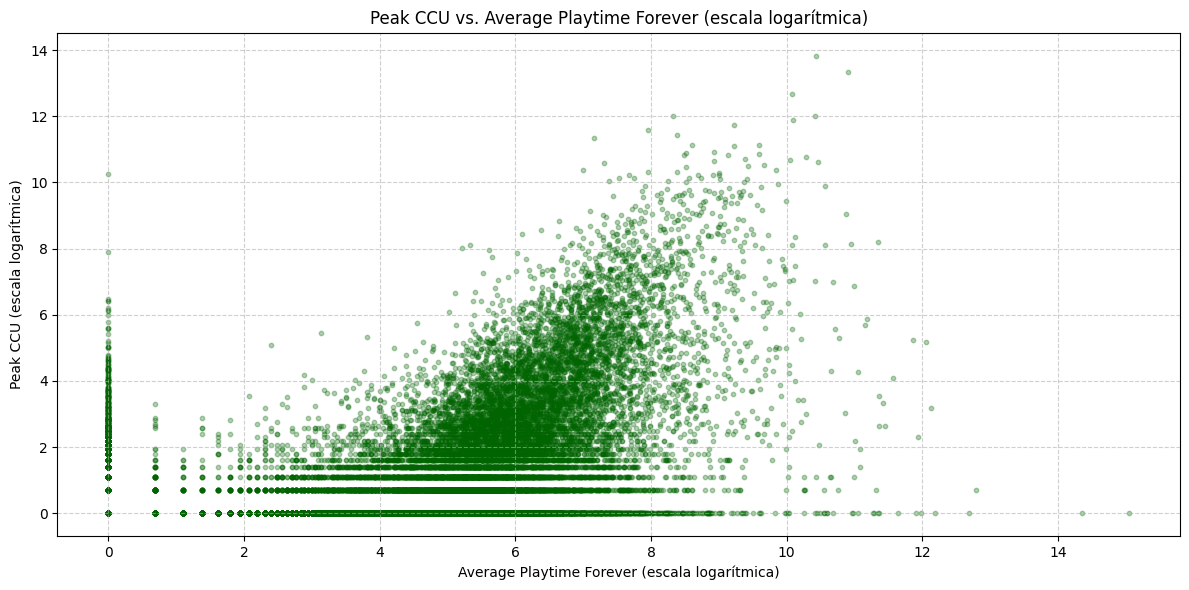

In [ ]:
plt.figure(figsize=(12, 6))
# Usamos np.log1p para manejar valores cero de ambas variables
plt.scatter(np.log1p(dataset['Average playtime forever']), np.log1p(dataset['Peak CCU']), alpha=0.3, s=10, color='darkgreen')
plt.xlabel('Average Playtime Forever (escala logarítmica)')
plt.ylabel('Peak CCU (escala logarítmica)')
plt.title('Peak CCU vs. Average Playtime Forever (escala logarítmica)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

El gráfico de dispersión con ambas variables en escala logarítmica nos muestra una **correlación positiva, aunque con una alta dispersión**. Esto significa que, en general, los juegos que tienen un mayor tiempo promedio de juego también tienden a tener picos más altos de jugadores concurrentes, y viceversa. Sin embargo, hay muchos casos atípicos: juegos con alto `Peak CCU` y bajo `Average playtime forever` (juegos muy populares pero de corta duración) y juegos con bajo `Peak CCU` pero alto `Average playtime forever` (juegos de nicho con una base de jugadores muy dedicada).

La densa concentración en la esquina inferior izquierda indica que la gran mayoría de los juegos tienen bajo `Peak CCU` y bajo `Average playtime forever`, lo que es consistente con nuestras observaciones anteriores sobre la distribución de ambas variables.

### Correlación Cuantitativa (Coeficiente de Pearson)

In [ ]:
import numpy as np

correlation = np.log1p(dataset['Peak CCU']).corr(np.log1p(dataset['Average playtime forever']))
print(f"Coeficiente de correlación de Pearson entre Peak CCU (log) y Average playtime forever (log): {correlation:.2f}")

Coeficiente de correlación de Pearson entre Peak CCU (log) y Average playtime forever (log): 0.61


El coeficiente de correlación de Pearson de **{correlation:.2f}** confirma una **correlación positiva moderada** entre el `Peak CCU` y el `Average playtime forever` cuando ambas variables se transforman logarítmicamente. Esto sugiere que, a medida que un juego atrae a más jugadores concurrentes, es probable que también los mantenga involucrados por más tiempo, aunque la relación no es perfecta y otros factores también influyen en el engagement.

### Peak CCU vs. Genre (Categórica)

Para entender qué géneros son los más jugados, analizaremos la distribución de 'Peak CCU' (nuestra métrica de popularidad) por género. Dado que un juego puede tener múltiples géneros y 'Peak CCU' tiene una distribución altamente asimétrica, usaremos el 'Peak CCU' promedio para cada género y luego visualizaremos los géneros con los valores más altos.

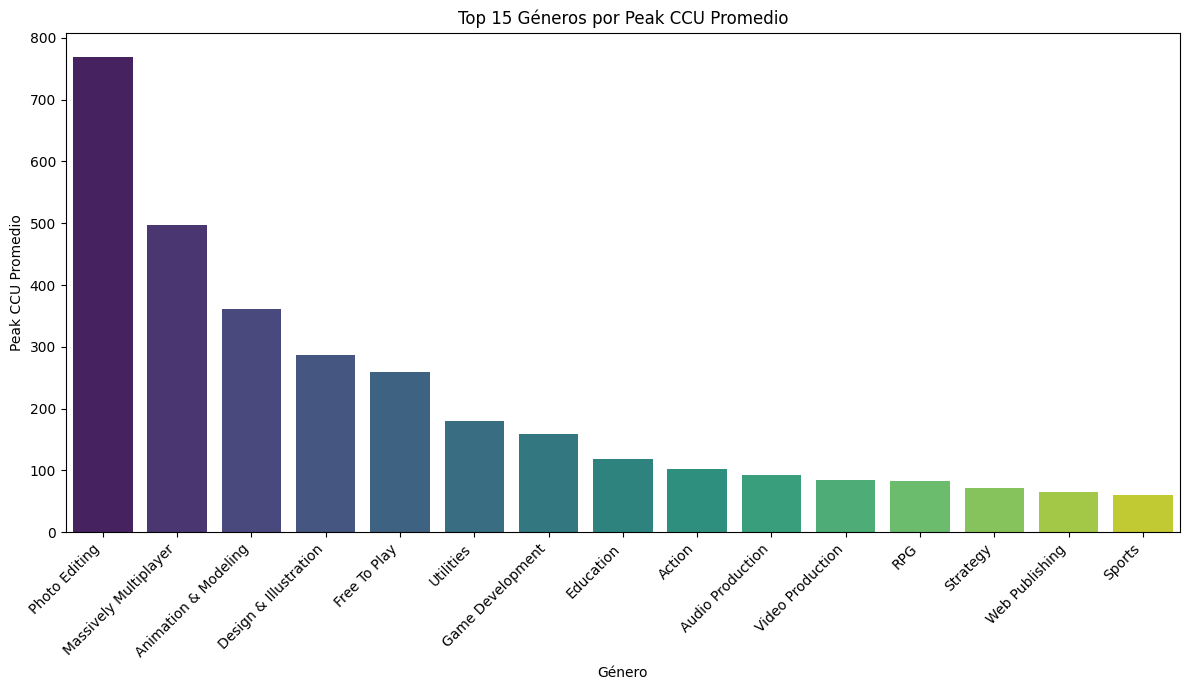

Top 15 Géneros por Peak CCU Promedio:
Genre
Photo Editing            769.606742
Massively Multiplayer    497.820763
Animation & Modeling     361.231092
Design & Illustration    286.000000
Free To Play             259.536985
Utilities                179.596262
Game Development         158.933333
Education                117.951754
Action                   101.884353
Audio Production          92.278027
Video Production          84.401786
RPG                       83.019929
Strategy                  72.227115
Web Publishing            65.072727
Sports                    60.660148
Name: Peak CCU, dtype: float64


In [ ]:
# Crear una copia del dataset para no modificar el original al expandir géneros
dataset_genres_expanded = dataset.copy()

# Expandir la columna 'Genre' donde hay múltiples géneros por juego
dataset_genres_expanded['Genre'] = dataset_genres_expanded['Genre'].str.split(',')
dataset_genres_expanded = dataset_genres_expanded.explode('Genre')
dataset_genres_expanded['Genre'] = dataset_genres_expanded['Genre'].str.strip()

# Calcular el Peak CCU promedio por cada género
genre_peak_ccu = dataset_genres_expanded.groupby('Genre')['Peak CCU'].mean().sort_values(ascending=False)

# Seleccionar los 15 géneros con mayor Peak CCU promedio
top_15_genres_peak_ccu = genre_peak_ccu.head(15)

plt.figure(figsize=(12, 7))
sns.barplot(x=top_15_genres_peak_ccu.index, y=top_15_genres_peak_ccu.values, palette='viridis', hue=top_15_genres_peak_ccu.index, legend=False)
plt.title('Top 15 Géneros por Peak CCU Promedio')
plt.xlabel('Género')
plt.ylabel('Peak CCU Promedio')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Top 15 Géneros por Peak CCU Promedio:")
print(top_15_genres_peak_ccu)

El gráfico muestra los 15 géneros de videojuegos con el 'Peak CCU' promedio más alto. Esto nos da una indicación de qué tipos de juegos tienden a atraer a la mayor cantidad de jugadores concurrentes. Podemos observar que ciertos géneros dominan en términos de popularidad instantánea, lo que puede estar relacionado con factores como la naturaleza competitiva, la capacidad de ser jugados en línea o la base de fans establecida.

Es importante recordar que 'Peak CCU' es una métrica de popularidad en un momento dado y no necesariamente refleja el tiempo de juego a largo plazo o la satisfacción del jugador, aunque ya vimos una correlación positiva moderada entre 'Peak CCU' y 'Average playtime forever'. Este análisis nos ayuda a responder la pregunta de investigación sobre qué géneros son los más jugados a nivel mundial.

### Peak CCU vs. Primer Género (Categórica)

Vamos a realizar el mismo análisis, pero considerando únicamente el primer género listado en la columna 'Genre' para cada juego. Esto puede dar una perspectiva diferente sobre qué géneros son los más populares si se considera su clasificación principal.

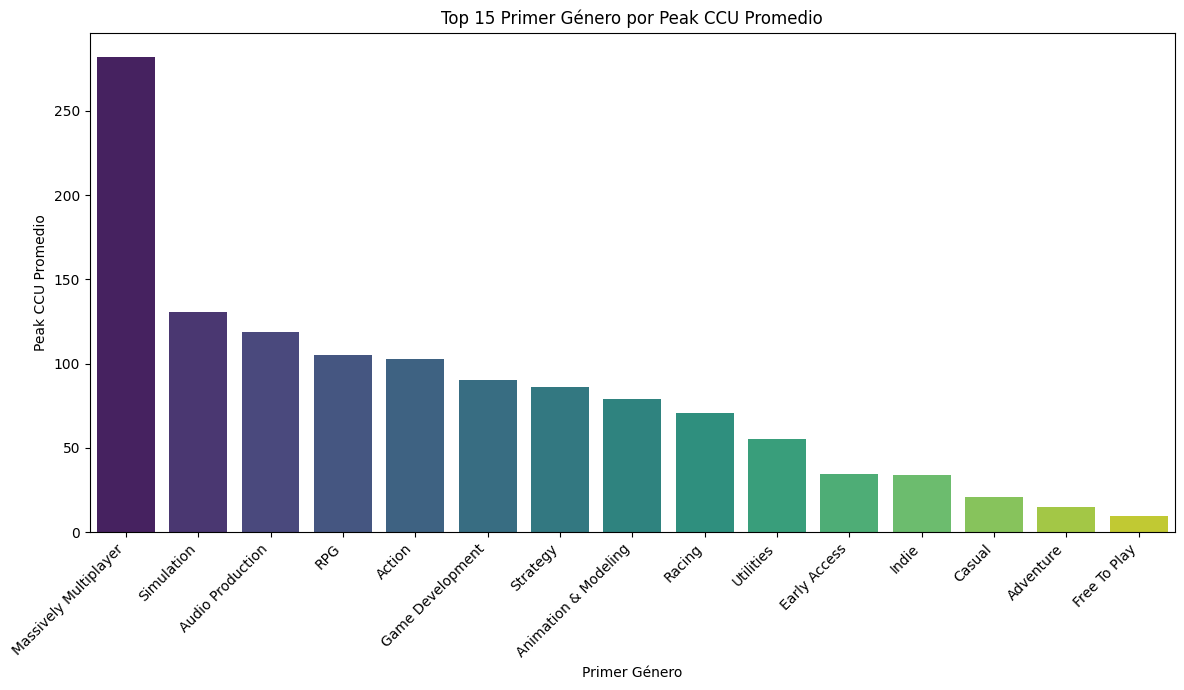

Top 15 Primer Género por Peak CCU Promedio:
First_Genre
Massively Multiplayer    282.113514
Simulation               130.691164
Audio Production         118.521739
RPG                      104.959717
Action                   102.620348
Game Development          90.166667
Strategy                  86.148077
Animation & Modeling      79.165217
Racing                    70.829358
Utilities                 55.189802
Early Access              34.687500
Indie                     33.731065
Casual                    21.092331
Adventure                 14.748256
Free To Play               9.589138
Name: Peak CCU, dtype: float64


In [ ]:
# Crear una copia del dataset para no modificar el original
dataset_first_genre = dataset.copy()

# Extraer solo el primer género de la columna 'Genre'
dataset_first_genre['First_Genre'] = dataset_first_genre['Genre'].str.split(',').str[0].str.strip()

# Calcular el Peak CCU promedio por el primer género
first_genre_peak_ccu = dataset_first_genre.groupby('First_Genre')['Peak CCU'].mean().sort_values(ascending=False)

# Seleccionar los 15 primeros géneros con mayor Peak CCU promedio
top_15_first_genre_peak_ccu = first_genre_peak_ccu.head(15)

plt.figure(figsize=(12, 7))
sns.barplot(x=top_15_first_genre_peak_ccu.index, y=top_15_first_genre_peak_ccu.values, palette='viridis', hue=top_15_first_genre_peak_ccu.index, legend=False)
plt.title('Top 15 Primer Género por Peak CCU Promedio')
plt.xlabel('Primer Género')
plt.ylabel('Peak CCU Promedio')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Top 15 Primer Género por Peak CCU Promedio:")
print(top_15_first_genre_peak_ccu)

##Conclusión Final — Análisis del Mercado de Videojuegos en Steam
El análisis exploratorio sobre 120.919 títulos de Steam permitió responder con claridad la pregunta central: ¿Qué tipos o generos son los más jugados a nivel mundial?

El mercado es profundamente desigual. Tanto el Peak CCU como el Average Playtime presentan medianas de 0, lo que significa que más del 50% de los juegos no registra jugadores ni tiempo de juego. El éxito está concentrado en una pequeña minoría de títulos, con un máximo de más de 1.000.000 de jugadores simultáneos frente a una media de apenas 55.

Los géneros más populares son Massively Multiplayer, Simulation y Action. Al analizar el Peak CCU promedio por género, estos tres lideran de forma consistente, tanto al considerar todos los géneros de un juego como únicamente el género principal. Esto indica que los juegos multijugador masivos y los simuladores concentran las comunidades más grandes y activas.

La popularidad y el engagement van de la mano. Se encontró una correlación positiva moderada (r = 0,61) entre Peak CCU y Average Playtime en escala logarítmica, lo que indica que los juegos que atraen más jugadores también tienden a retenerlos por más tiempo.

El precio tiene un impacto limitado. La distribución de precios es asimétrica, con una mediana de $4,24 USD. Los juegos gratuitos muestran una leve ventaja en los percentiles superiores de popularidad, pero la mayoría de los títulos —sean gratuitos o de pago— no logra tracción significativa.

En síntesis: el éxito en Steam no depende del género elegido por sí solo, sino de la capacidad del juego de construir una comunidad activa. Los géneros multijugador y de simulación ofrecen las condiciones más favorables para lograrlo.
